# Машинное обучение. Задание 1

## Подготовка данных: загрузка и визуализация, импутирование и интерполяция

Выполнил: Егор Пирогов
НИУ ВШЭ — Пермь, кафедра информационных технологий в бизнесе, 2026

### Набор данных

Взят собственный набор вместо предложенных преподавателем (доп. часть, +1 балл).

Источник — [Open-Meteo Archive API](https://open-meteo.com/en/docs/historical-weather-api),
реанализ ERA5 (ECMWF), лицензия CC-BY 4.0. Точка — Пермь (58.03° с.ш., 56.27° в.д.),
период — весь 2024 год с часовым шагом, то есть 8784 наблюдения. Переменные:
температура, относительная влажность, приземное давление, скорость и направление
ветра, осадки.

Запрос к API вынесен в `scripts/download_data.py`, ноутбук читает локальный CSV
и не требует интернета.

Целевая оценка — 9 баллов: 8 за базовую часть и 1 за свой набор данных с
дополнительным типом диаграммы.

### Импорт библиотек и настройка оформления

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import lagrange, CubicSpline

# Вспомогательные функции работы: оформление осей и методы импутации.
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from hw_utils import (
    style_axes, fill_prev3, error_stats,
    sigma_outliers, iqr_outliers,
    MONTHS_SHORT, MONTHS_FULL, RUMBS_8, RUMBS_16,
)

DATA = Path.cwd().parent / "data" / "raw" / "perm_2024_hourly.csv"
FIG = Path.cwd().parent / "figures"
FIG.mkdir(exist_ok=True)

# Кириллица в подписях и корректный знак «минус» для отрицательных температур.
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["figure.facecolor"] = "white"
sns.set_style("white")

np.random.seed(42)  # воспроизводимость
pd.set_option("display.precision", 3)

print("Проверка кириллицы: Пермь, температура −32.5 °C")
print("pandas", pd.__version__, "| numpy", np.__version__)

Проверка кириллицы: Пермь, температура −32.5 °C
pandas 3.0.5 | numpy 2.4.6


---
## Пункт 1. Исходные данные

Файл скачивается один раз скриптом `scripts/download_data.py` и хранится в
репозитории работы, чтобы результат воспроизводился без обращения к сети.

In [2]:
if not DATA.exists():
    raise FileNotFoundError(
        f"Не найден файл {DATA}.\n"
        "Выполните: .venv/bin/python scripts/download_data.py"
    )

print(f"Файл: {DATA.name}")
print(f"Размер: {DATA.stat().st_size / 1024:.1f} КБ")
print(f"Строк в файле: {sum(1 for _ in DATA.open())}")
print()
print("Первые строки файла как есть:")
print("".join(DATA.open(encoding="utf-8").readlines()[:5]))

Файл: perm_2024_hourly.csv
Размер: 387.0 КБ
Строк в файле: 8788

Первые строки файла как есть:
latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
58.03163,56.27451,150.0,18000,Asia/Yekaterinburg,GMT+5

time,temperature_2m (°C),relative_humidity_2m (%),surface_pressure (hPa),wind_speed_10m (m/s),wind_direction_10m (°),precipitation (mm)
2024-01-01T00:00,-11.3,81,979.1,4.79,61,0.30



Структура CSV от Open-Meteo нестандартная: первые три строки служебные
(две строки метаданных о точке наблюдения и пустая строка-разделитель), и лишь
четвёртая строка содержит имена колонок. Поэтому при чтении указывается
`skiprows=3` — иначе pandas примет метаданные за заголовок и все столбцы
получат тип `object` вместо чисел.

---
## Пункт 2. Загрузка данных, преобразование типов, диаграммы

### 2.1. Паспорт точки наблюдения

In [3]:
meta = pd.read_csv(DATA, nrows=1)
print("Метаданные точки наблюдения:")
for col in meta.columns:
    print(f"  {col:24s} = {meta[col].iloc[0]}")

Метаданные точки наблюдения:
  latitude                 = 58.03163
  longitude                = 56.27451
  elevation                = 150.0
  utc_offset_seconds       = 18000
  timezone                 = Asia/Yekaterinburg
  timezone_abbreviation    = GMT+5


### 2.2. Чтение таблицы наблюдений и приведение типов

In [4]:
df = pd.read_csv(DATA, skiprows=3)
print("Исходные имена колонок (с единицами измерения):")
for c in df.columns:
    print("   ", c)

# Короткие имена для кода + отдельный словарь единиц для подписей осей.
df.columns = ["time", "temp", "humidity", "pressure",
              "wind_speed", "wind_dir", "precip"]

UNITS = {
    "temp": "Температура воздуха, °C",
    "humidity": "Относительная влажность, %",
    "pressure": "Приземное давление, гПа",
    "wind_speed": "Скорость ветра, м/с",
    "wind_dir": "Направление ветра, °",
    "precip": "Осадки, мм",
}

# Ключевое преобразование типов: строка -> datetime -> индекс временного ряда.
print("\nТип колонки time до преобразования:", df["time"].dtype)
df["time"] = pd.to_datetime(df["time"])
print("Тип колонки time после преобразования:", df["time"].dtype)

df = df.set_index("time").sort_index()

# Производные признаки для группировок и диаграмм.
df["month"] = df.index.month
df["hour"] = df.index.hour
df["doy"] = df.index.dayofyear
df["date"] = df.index.date

df.head()

Исходные имена колонок (с единицами измерения):
    time
    temperature_2m (°C)
    relative_humidity_2m (%)
    surface_pressure (hPa)
    wind_speed_10m (m/s)
    wind_direction_10m (°)
    precipitation (mm)

Тип колонки time до преобразования: str
Тип колонки time после преобразования: datetime64[us]


,temp,humidity,pressure,wind_speed,wind_dir,precip,month,hour,doy,date
time,,,,,,,,,,
2024-01-01 00:00:00,-11.3,81,979.1,4.79,61,0.3,1,0,1,2024-01-01
2024-01-01 01:00:00,-10.7,81,978.1,4.99,57,0.5,1,1,1,2024-01-01
2024-01-01 02:00:00,-10.5,83,977.0,5.24,55,1.0,1,2,1,2024-01-01
2024-01-01 03:00:00,-10.4,83,976.4,5.50,53,0.9,1,3,1,2024-01-01
2024-01-01 04:00:00,-10.5,81,976.1,5.56,52,0.5,1,4,1,2024-01-01


### 2.3. Контроль качества данных

In [5]:
print(f"Размерность таблицы: {df.shape[0]} наблюдений × {df.shape[1]} признаков")
print(f"Период: {df.index.min()} — {df.index.max()}")
print(f"366 суток × 24 часа = {366 * 24} (2024 — високосный год)")

print("\nПропуски по столбцам:")
print(df[list(UNITS)].isna().sum().to_string())

full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
missing_stamps = full_range.difference(df.index)
print(f"\nПропущенных отметок времени в сетке: {len(missing_stamps)}")
print(f"Ряд регулярный и непрерывный: {missing_stamps.empty}")

print("\nОписательные статистики:")
df[list(UNITS)].describe().T

Размерность таблицы: 8784 наблюдений × 10 признаков
Период: 2024-01-01 00:00:00 — 2024-12-31 23:00:00
366 суток × 24 часа = 8784 (2024 — високосный год)

Пропуски по столбцам:
temp          0
humidity      0
pressure      0
wind_speed    0
wind_dir      0
precip        0

Пропущенных отметок времени в сетке: 0
Ряд регулярный и непрерывный: True

Описательные статистики:


,count,mean,std,min,25%,50%,75%,max
temp,8784.0,3.440,12.125,-32.5,-4.800,2.7,13.50,30.90
humidity,8784.0,77.224,15.206,23.0,68.000,81.0,89.00,100.00
pressure,8784.0,996.738,11.622,953.1,988.875,997.1,1005.10,1031.40
wind_speed,8784.0,3.128,1.364,0.0,2.120,3.0,4.03,9.45
wind_dir,8784.0,201.597,91.804,1.0,145.000,222.0,259.00,360.00
precip,8784.0,0.076,0.366,0.0,0.000,0.0,0.00,10.40


Следствие для пункта 4. В наборе данных нет ни одного пропуска:
ERA5 — это реанализ, то есть результат работы модели, усваивающей наблюдения,
и он по построению даёт полное поле без лакун. Поэтому пропуски в пункте 4
создаются искусственно, прореживанием заведомо известного участка ряда.
Удалённые значения при этом известны точно, и качество каждого метода восстановления можно измерить, сравнив
оценку с настоящим значением.

---
### 2.4. Обязательные виды диаграмм

На каждой диаграмме выполнены требования методички: использован весь годовой
ряд из 8784 наблюдений вместо минимальной тысячи (число указано в заголовке),
оси подписаны по-русски с единицами измерения, на концах осей нарисованы стрелки
направления (аналог `arrows()` из примеров на R), построена основная и
вспомогательная сетка. Оформление вынесено в функцию `style_axes()` модуля
`scripts/hw_utils.py`.

#### 2.4.1. Линейная диаграмма — годовой ход температуры

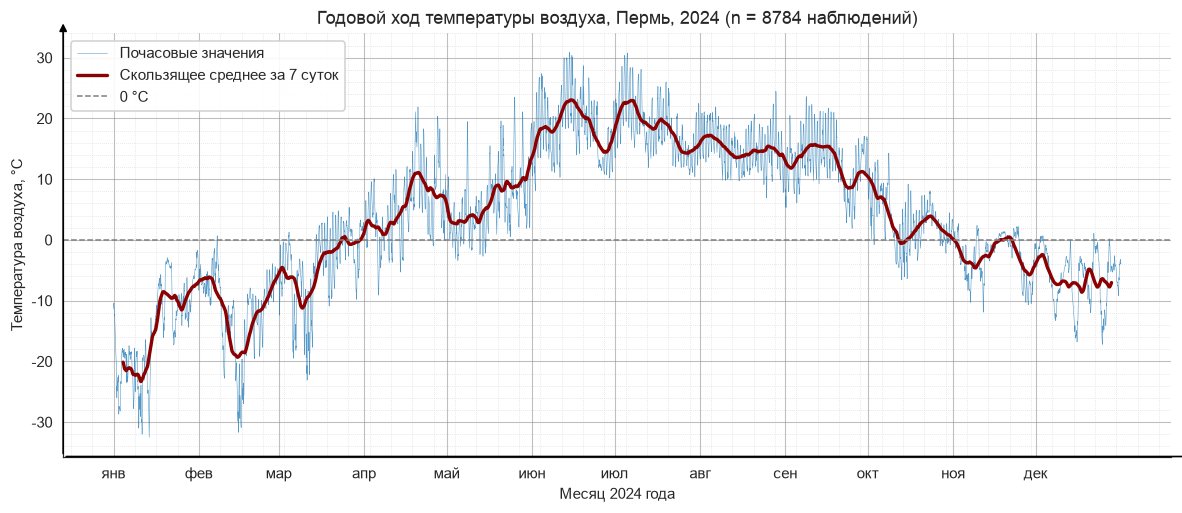

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(df.index, df["temp"], lw=0.35, color="tab:blue",
        alpha=0.75, label="Почасовые значения")
ax.plot(df.index, df["temp"].rolling(24 * 7, center=True).mean(),
        lw=2.2, color="darkred", label="Скользящее среднее за 7 суток")
ax.axhline(0, color="grey", ls="--", lw=1, label="0 °C")

style_axes(ax, "Месяц 2024 года", UNITS["temp"],
           f"Годовой ход температуры воздуха, Пермь, 2024 (n = {len(df)} наблюдений)")

ax.set_xticks([pd.Timestamp(2024, m, 1) for m in range(1, 13)])
ax.set_xticklabels(MONTHS_SHORT)
ax.legend(loc="upper left", framealpha=0.9)

fig.savefig(FIG / "01_line_temperature.png")
plt.show()

Ряд ведёт себя так, как и должен вести себя годовой ход температуры в умеренных
широтах: холодная половина года в начале и конце, тёплая — в середине. Тонкая
линия почасовых значений образует «облако» вокруг сглаженной кривой, и ширина
этого облака зимой заметно больше, чем летом.

#### 2.4.2. Столбчатая диаграмма — месячные суммы осадков и средняя температура

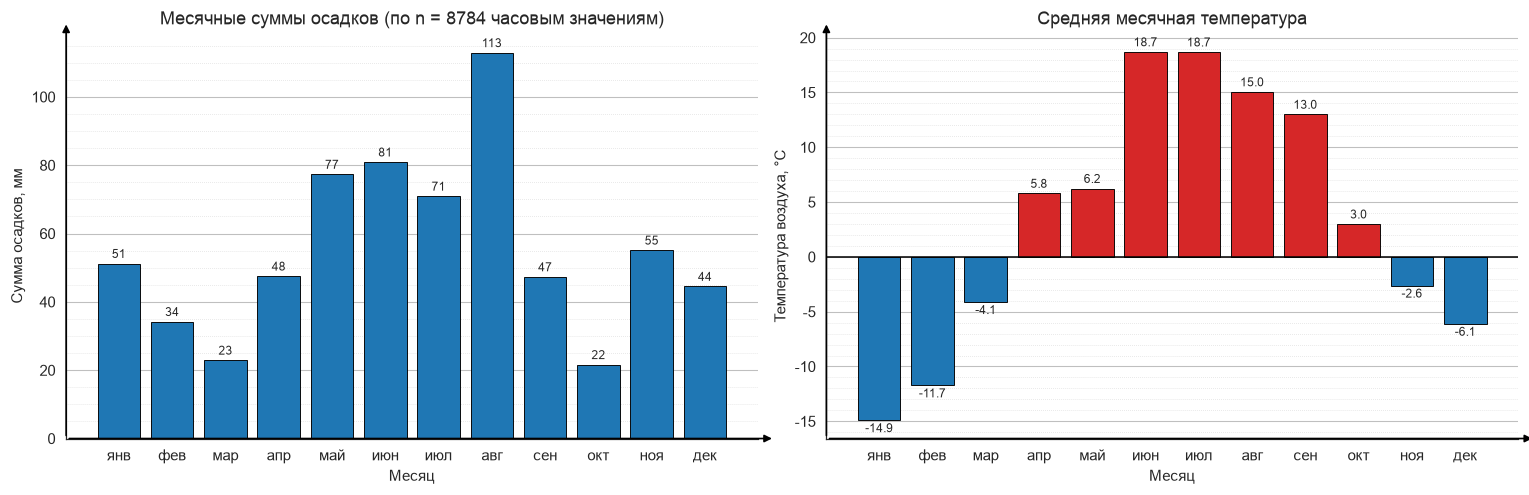

Годовая сумма осадков: 666 мм


In [7]:
monthly_precip = df["precip"].resample("ME").sum()
monthly_temp = df["temp"].resample("ME").mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

bars = axes[0].bar(range(1, 13), monthly_precip.values,
                   color="tab:blue", edgecolor="black", lw=0.6)
axes[0].bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
style_axes(axes[0], "Месяц", "Сумма осадков, мм",
           f"Месячные суммы осадков (по n = {len(df)} часовым значениям)",
           grid_axis="y")
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(MONTHS_SHORT)

colors = np.where(monthly_temp.values < 0, "tab:blue", "tab:red")
bars2 = axes[1].bar(range(1, 13), monthly_temp.values,
                    color=colors, edgecolor="black", lw=0.6)
axes[1].bar_label(bars2, fmt="%.1f", fontsize=8, padding=2)
axes[1].axhline(0, color="black", lw=1)
style_axes(axes[1], "Месяц", UNITS["temp"],
           "Средняя месячная температура", grid_axis="y")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(MONTHS_SHORT)

fig.tight_layout()
fig.savefig(FIG / "02_bar_monthly.png")
plt.show()

print("Годовая сумма осадков: %.0f мм" % monthly_precip.sum())

#### 2.4.3. Круговая диаграмма — повторяемость направлений ветра по 8 румбам

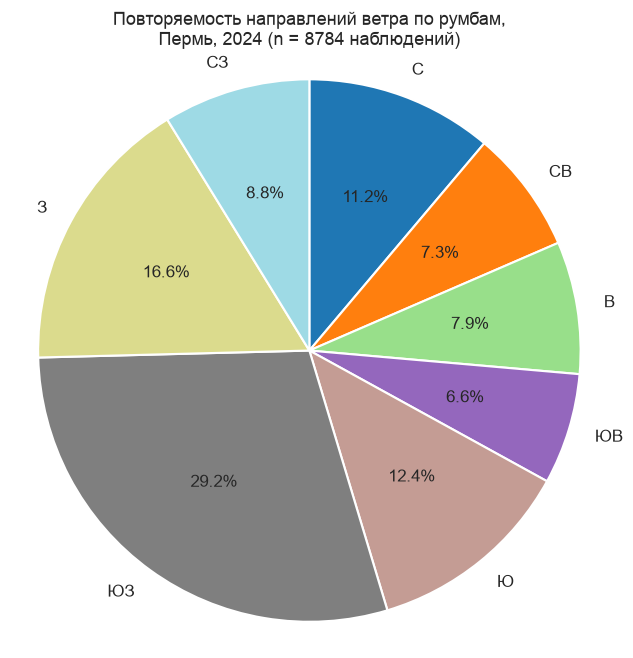

Повторяемость по румбам, %:
wind_dir
С     11.2
СВ     7.3
В      7.9
ЮВ     6.6
Ю     12.4
ЮЗ    29.2
З     16.6
СЗ     8.8


In [8]:
# Сектор «север» охватывает 337.5°..22.5°, поэтому шкала сдвигается на полсектора.
shifted = (df["wind_dir"] + 22.5) % 360
sector = pd.cut(shifted, bins=np.arange(0, 361, 45),
                labels=RUMBS_8, right=False, include_lowest=True)
counts = sector.value_counts().reindex(RUMBS_8)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(counts.values, labels=RUMBS_8, autopct="%1.1f%%",
       startangle=90, counterclock=False,
       colors=plt.cm.tab20(np.linspace(0, 1, 8)),
       wedgeprops=dict(edgecolor="white", lw=1.4),
       textprops=dict(fontsize=11))
ax.set_title(f"Повторяемость направлений ветра по румбам,\nПермь, 2024 "
             f"(n = {len(df)} наблюдений)")
ax.axis("equal")

fig.savefig(FIG / "03_pie_wind_sectors.png")
plt.show()

print("Повторяемость по румбам, %:")
print((counts / counts.sum() * 100).round(1).to_string())

Для круговой диаграммы подписи осей, сетка и стрелки направления неприменимы:
у неё нет декартовых осей, а доли секторов подписаны непосредственно на
диаграмме в процентах. Требование методички об оформлении осей относится к
линейным и столбчатым диаграммам.

#### 2.4.4. Скрипичная диаграмма — распределение температуры по месяцам

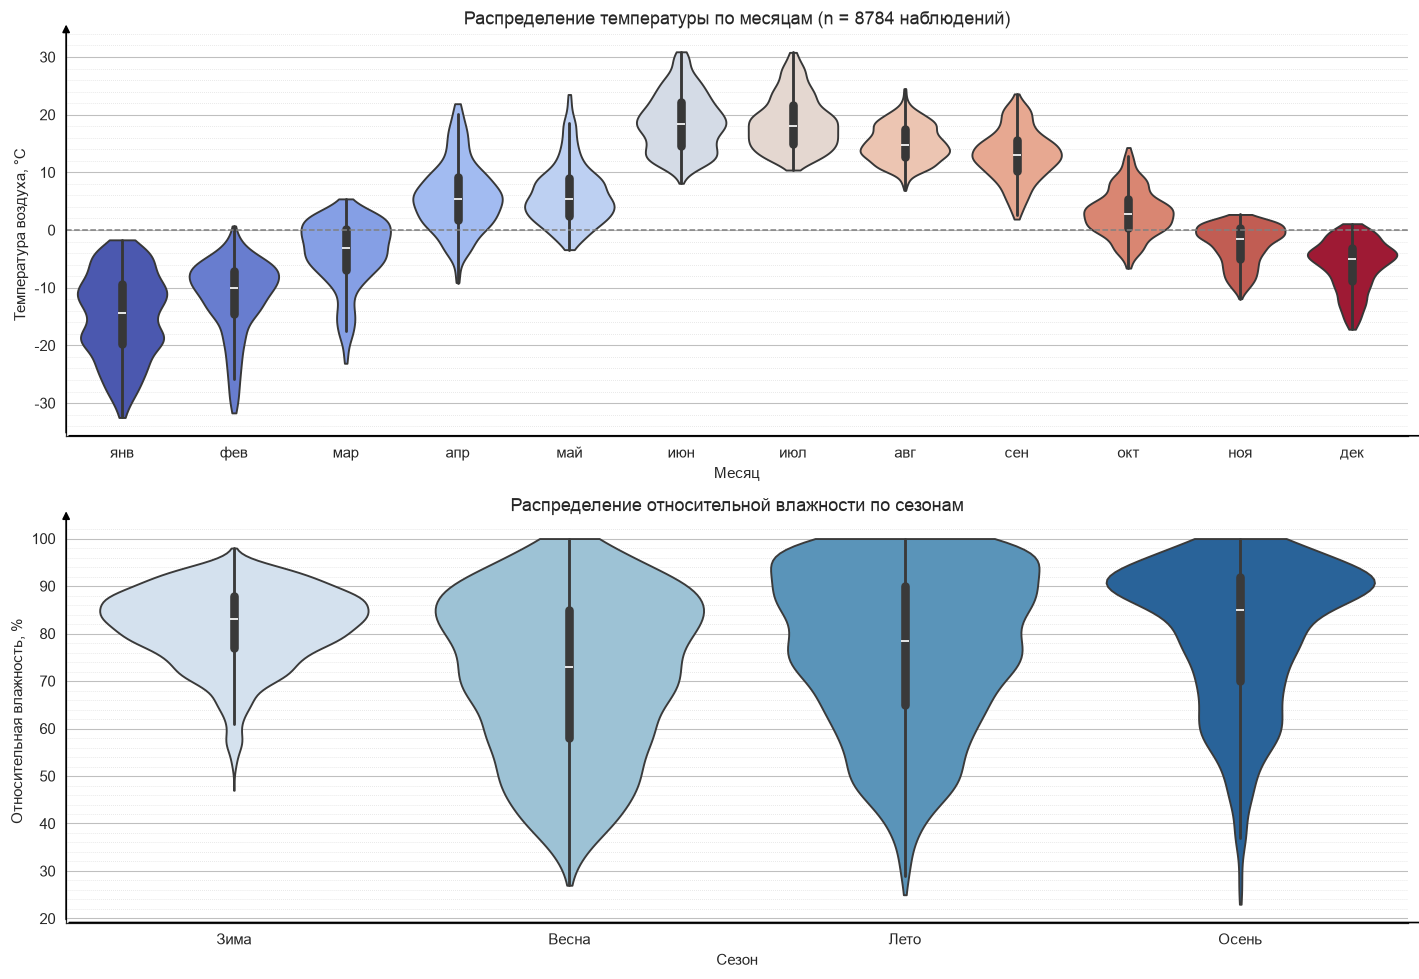

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

sns.violinplot(data=df, x="month", y="temp", inner="box",
               cut=0, density_norm="width", hue="month",
               palette="coolwarm", legend=False, ax=axes[0])
style_axes(axes[0], "Месяц", UNITS["temp"],
           f"Распределение температуры по месяцам (n = {len(df)} наблюдений)",
           grid_axis="y")
axes[0].set_xticks(range(12))
axes[0].set_xticklabels(MONTHS_SHORT)
axes[0].axhline(0, color="grey", ls="--", lw=1)

season = {12: "Зима", 1: "Зима", 2: "Зима", 3: "Весна", 4: "Весна", 5: "Весна",
          6: "Лето", 7: "Лето", 8: "Лето", 9: "Осень", 10: "Осень", 11: "Осень"}
df["season"] = df["month"].map(season)
order = ["Зима", "Весна", "Лето", "Осень"]

sns.violinplot(data=df, x="season", y="humidity", order=order, inner="box",
               cut=0, density_norm="width", hue="season", palette="Blues",
               legend=False, ax=axes[1])
style_axes(axes[1], "Сезон", UNITS["humidity"],
           "Распределение относительной влажности по сезонам", grid_axis="y")

fig.tight_layout()
fig.savefig(FIG / "04_violin_temp_humidity.png")
plt.show()

Скрипичная диаграмма показывает не только медиану и квартили (как box-plot),
но и форму распределения. Видно, что зимние месяцы дают широкие и
часто двугорбые «скрипки», а летние — узкие и компактные. Содержательная
интерпретация этого факта — в следующем разделе.

---
## Пункт 3. Качественный анализ предметной области

Предметная область — приземная метеорология умеренных широт, точка наблюдения
в Предуралье. Каждый вывод ниже подкреплён числом, рассчитанным по данным.

### 3.1. Суточный ход температуры

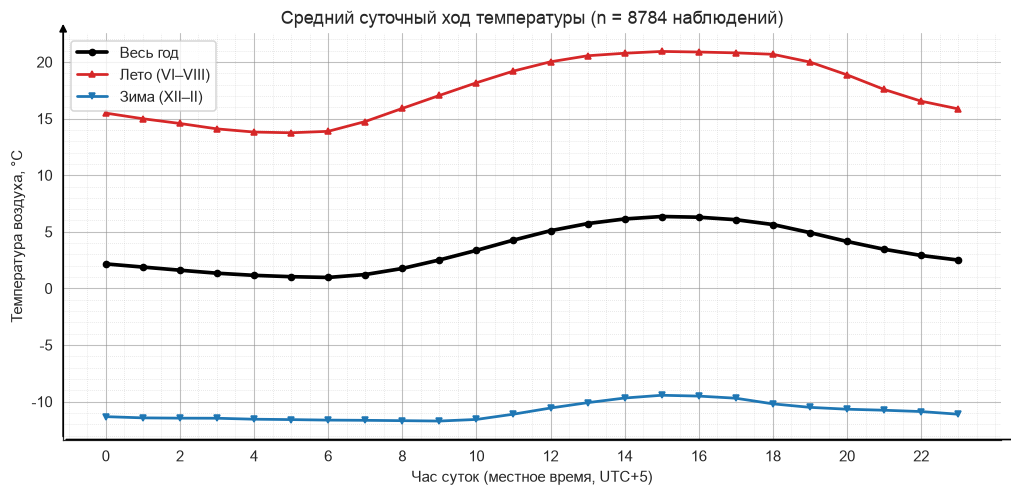

Минимум среднего суточного хода: 6 ч (1.0 °C)
Максимум среднего суточного хода: 15 ч (6.4 °C)
Амплитуда суточного хода летом: 7.2 °C
Амплитуда суточного хода зимой: 2.3 °C


In [10]:
hourly = df.groupby("hour")["temp"].mean()
summer_h = df[df["month"].isin([6, 7, 8])].groupby("hour")["temp"].mean()
winter_h = df[df["month"].isin([12, 1, 2])].groupby("hour")["temp"].mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(hourly.index, hourly.values, lw=2.4, color="black", marker="o",
        ms=4, label="Весь год")
ax.plot(summer_h.index, summer_h.values, lw=1.8, color="tab:red",
        marker="^", ms=4, label="Лето (VI–VIII)")
ax.plot(winter_h.index, winter_h.values, lw=1.8, color="tab:blue",
        marker="v", ms=4, label="Зима (XII–II)")

style_axes(ax, "Час суток (местное время, UTC+5)", UNITS["temp"],
           f"Средний суточный ход температуры (n = {len(df)} наблюдений)")
ax.set_xticks(range(0, 24, 2))
ax.legend()

fig.savefig(FIG / "05_daily_cycle.png")
plt.show()

print(f"Минимум среднего суточного хода: {hourly.idxmin()} ч ({hourly.min():.1f} °C)")
print(f"Максимум среднего суточного хода: {hourly.idxmax()} ч ({hourly.max():.1f} °C)")
print(f"Амплитуда суточного хода летом: {summer_h.max() - summer_h.min():.1f} °C")
print(f"Амплитуда суточного хода зимой: {winter_h.max() - winter_h.min():.1f} °C")

### 3.2. Связи между метеорологическими величинами

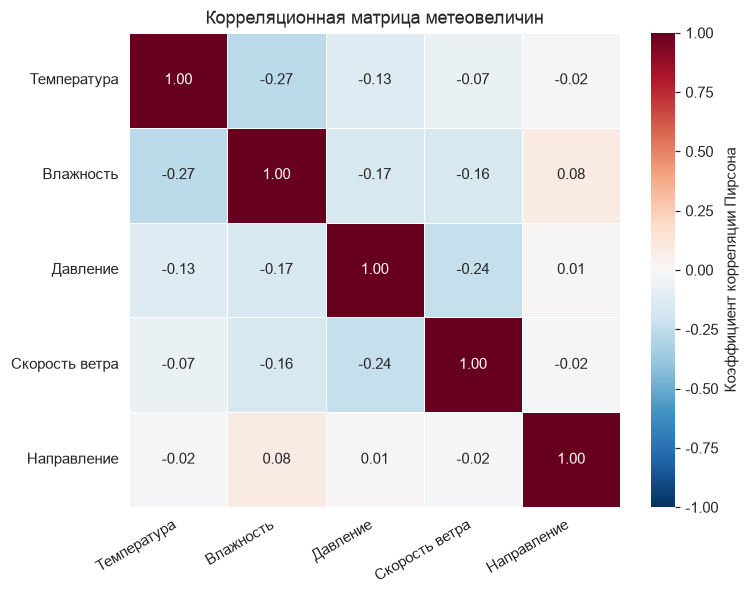

Корреляция температура ↔ влажность (весь ряд): -0.269
Корреляция осадки ↔ изменение давления: -0.085

Средние по месяцам:


,temp,humidity,pressure
январь,-14.9,78.9,994.5
февраль,-11.7,77.8,1001.1
март,-4.1,78.6,997.9
апрель,5.8,70.8,997.5
май,6.2,63.5,995.3
июнь,18.7,69.7,990.5
июль,18.7,75.8,992.3
август,15.0,83.5,990.5
сентябрь,13.0,75.1,1007.1
октябрь,3.0,78.4,1002.7


In [11]:
corr = df[list(UNITS)[:-1]].corr()

fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=ax)
ax.set_title("Корреляционная матрица метеовеличин")
labels = ["Температура", "Влажность", "Давление", "Скорость ветра", "Направление"]
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_yticklabels(labels, rotation=0)

fig.savefig(FIG / "06_corr_matrix.png")
plt.show()

print(f"Корреляция температура ↔ влажность (весь ряд): {corr.loc['temp', 'humidity']:.3f}")
print(f"Корреляция осадки ↔ изменение давления: "
      f"{df['precip'].corr(df['pressure'].diff()):.3f}")

monthly_stats = df.groupby("month")[["temp", "humidity", "pressure"]].mean()
monthly_stats.index = MONTHS_FULL
print("\nСредние по месяцам:")
monthly_stats.round(1)

### 3.3. Выводы по предметной области

1\. Климат резко континентальный: средняя температура +3.4 °C при размахе от
−32.5 до +30.9 °C, то есть годовая амплитуда больше 63 градусов. Пермь удалена
от океана, а Уральские горы ослабляют западный перенос.

2\. Суточный минимум приходится на 6 часов, максимум на 15 — не на полдень,
потому что почва отдаёт тепло и после максимума солнечной радиации. Летом
амплитуда суточного хода 7.2 °C, зимой 2.3 °C: зимой солнце низкое и часта
облачность. Поэтому для интерполяции в пункте 4 взят летний участок — на нём
разница между методами заметна.

3\. Температура и влажность связаны обратно: коэффициент корреляции
отрицательный. Тёплый воздух способен удержать больше водяного пара, поэтому
дневной нагрев снижает относительную влажность, а ночное остывание поднимает её
почти до 100 % — отсюда роса и туманы под утро.

4\. Осадки идут при падении давления, то есть при приближении циклона.

5\. Распределение осадков асимметрично: большинство часов нулевые, редкие дают
крупные значения. Среднее здесь смещено редкими ливнями, поэтому на столбчатой
диаграмме осадки просуммированы за месяц.

6\. Зимние «скрипки» шире летних и часто двугорбые: зимой Пермь попеременно под
арктическими вторжениями (морозы до −30 °C) и атлантическими циклонами
(оттепели около 0 °C). Летом режим один, поэтому распределение компактное.

---
## Пункт 4. Методы заполнения пропущенных значений

### 4.1. Формирование пропусков прореживанием

Берётся непрерывный участок ряда температуры длиной 48 часов (двое летних
суток), из которого удаляется каждое второе значение. Получается
24 пропуска, что удовлетворяет требованию «не менее 20 значений».

Участок выбран летним осознанно: как показано в пункте 3, летом суточный ход
выражен максимально, поэтому восстанавливаемый сигнал гладкий и периодичный —
на нём различия между методами видны отчётливо.

In [12]:
SEG_START, SEG_END = "2024-07-10", "2024-07-11"
seg = df.loc[SEG_START:SEG_END, "temp"]

y_full = seg.to_numpy(dtype=float)
x = np.arange(len(y_full), dtype=float)      # часы от начала участка

known_mask = np.zeros(len(y_full), dtype=bool)
known_mask[::2] = True                        # оставляем каждое второе
missing_mask = ~known_mask

x_known, y_known = x[known_mask], y_full[known_mask]
x_missing, y_truth = x[missing_mask], y_full[missing_mask]

work = np.where(known_mask, y_full, np.nan)   # ряд с пропусками

print(f"Участок: {seg.index[0]} — {seg.index[-1]}")
print(f"Длина участка:            {len(y_full)} значений")
print(f"Известные (каждое второе): {known_mask.sum()}")
print(f"Удалённые (пропуски):      {missing_mask.sum()}  ← требуется ≥ 20")
print(f"Температура на участке: от {y_full.min():.1f} до {y_full.max():.1f} °C")

Участок: 2024-07-10 00:00:00 — 2024-07-11 23:00:00
Длина участка:            48 значений
Известные (каждое второе): 24
Удалённые (пропуски):      24  ← требуется ≥ 20
Температура на участке: от 17.4 до 28.1 °C


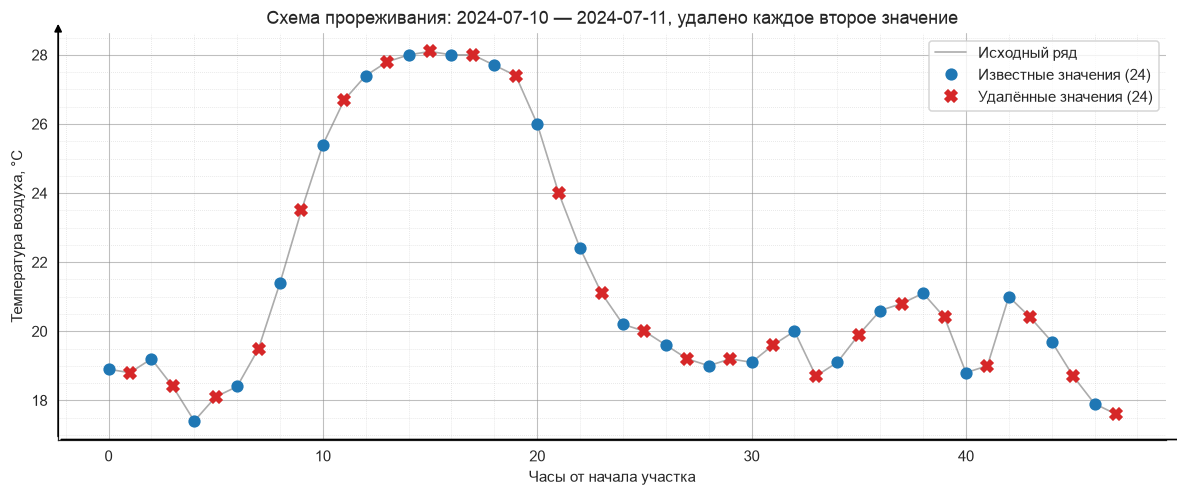

In [13]:
fig, ax = plt.subplots(figsize=(13, 4.8))

ax.plot(x, y_full, lw=1.1, color="grey", alpha=0.65, label="Исходный ряд")
ax.plot(x_known, y_known, "o", ms=7, color="tab:blue",
        label=f"Известные значения ({known_mask.sum()})")
ax.plot(x_missing, y_truth, "X", ms=8, color="tab:red",
        label=f"Удалённые значения ({missing_mask.sum()})")

style_axes(ax, "Часы от начала участка", UNITS["temp"],
           f"Схема прореживания: {SEG_START} — {SEG_END}, удалено каждое второе значение")
ax.legend()

fig.savefig(FIG / "07_gaps_scheme.png")
plt.show()

### 4.2. Заполнение средним и медианой ряда

Простейший подход: все пропуски заменяются одной константой — средним или
медианой известных значений участка.

Среднее известных значений: 21.51 °C
Медиана известных значений: 20.10 °C


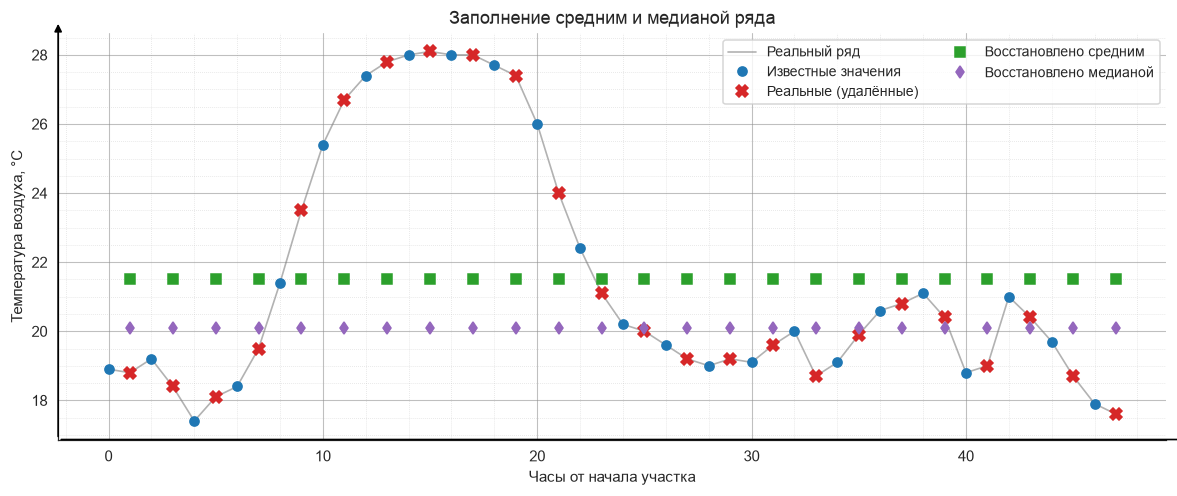

In [14]:
restored = {}   # сюда собираются результаты всех методов

restored["Среднее"] = np.full(len(x_missing), y_known.mean())
restored["Медиана"] = np.full(len(x_missing), np.median(y_known))

print(f"Среднее известных значений: {y_known.mean():.2f} °C")
print(f"Медиана известных значений: {np.median(y_known):.2f} °C")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(x, y_full, lw=1.1, color="grey", alpha=0.6, label="Реальный ряд")
ax.plot(x_known, y_known, "o", ms=6, color="tab:blue", label="Известные значения")
ax.plot(x_missing, y_truth, "X", ms=8, color="tab:red", label="Реальные (удалённые)")
ax.plot(x_missing, restored["Среднее"], "s", ms=6, color="tab:green",
        label="Восстановлено средним")
ax.plot(x_missing, restored["Медиана"], "d", ms=6, color="tab:purple",
        label="Восстановлено медианой")

style_axes(ax, "Часы от начала участка", UNITS["temp"],
           "Заполнение средним и медианой ряда")
ax.legend(ncol=2, fontsize=9)

fig.savefig(FIG / "08_impute_mean_median.png")
plt.show()

Восстановленные значения выстраиваются в горизонтальную «полку», тогда как
реальные образуют суточную волну. Метод сохраняет только общий уровень, теряя и
суточный ход, и локальный тренд; ошибка выходит порядка половины амплитуды.

### 4.3. Заполнение средним трёх предыдущих известных значений

Каузальный метод: для каждого пропуска берётся среднее трёх предыдущих
известных значений. Восстановленные оценки в число опорных не включаются —
иначе метод начал бы опираться на собственные результаты и ошибка накапливалась
бы вдоль ряда.

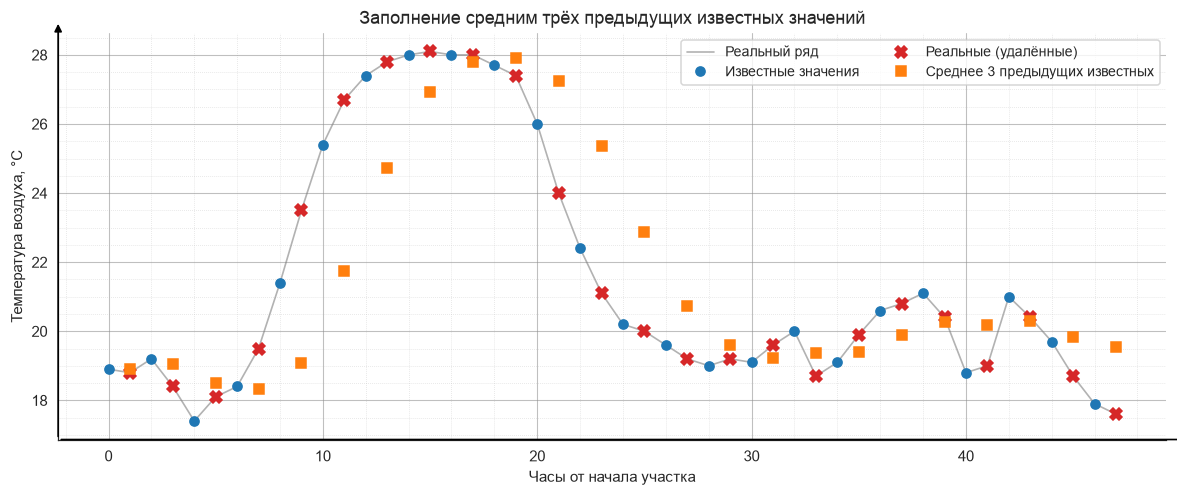

Среднее отклонение на участках роста температуры:   -1.21 °C
Среднее отклонение на участках падения температуры: +1.36 °C


In [15]:
prev3_full = fill_prev3(work, known_mask)
restored["3 предыдущих"] = prev3_full[missing_mask]

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(x, y_full, lw=1.1, color="grey", alpha=0.6, label="Реальный ряд")
ax.plot(x_known, y_known, "o", ms=6, color="tab:blue", label="Известные значения")
ax.plot(x_missing, y_truth, "X", ms=8, color="tab:red", label="Реальные (удалённые)")
ax.plot(x_missing, restored["3 предыдущих"], "s", ms=6, color="tab:orange",
        label="Среднее 3 предыдущих известных")

style_axes(ax, "Часы от начала участка", UNITS["temp"],
           "Заполнение средним трёх предыдущих известных значений")
ax.legend(ncol=2, fontsize=9)

fig.savefig(FIG / "09_impute_prev3.png")
plt.show()

diff = restored["3 предыдущих"] - y_truth
rising = diff[np.gradient(y_full)[missing_mask] > 0].mean()
falling = diff[np.gradient(y_full)[missing_mask] < 0].mean()
print(f"Среднее отклонение на участках роста температуры:   {rising:+.2f} °C")
print(f"Среднее отклонение на участках падения температуры: {falling:+.2f} °C")

Метод учитывает локальный уровень ряда и потому заметно точнее константы, но
обладает систематическим запаздыванием: он смотрит только назад, поэтому на
участках роста температуры занижает значения, а на участках падения — завышает.
Числа под графиком показывают этот сдвиг явно: отклонения на растущих и
падающих участках имеют противоположные знаки. Это классическое свойство любого
каузального сглаживания.

### 4.4. Интерполяционный многочлен Лагранжа

Многочлен Лагранжа строится по всем 24 известным узлам сразу, то есть его
степень равна 23.

In [16]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # переполнение здесь ожидаемо
    with np.errstate(over="ignore", invalid="ignore"):
        poly_global = lagrange(x_known, y_known)
        lagrange_global = np.polyval(poly_global, x_missing)

restored["Лагранж (глобальный)"] = lagrange_global

print(f"Степень многочлена: {len(x_known) - 1}")
print(f"Реальная температура на участке: от {y_full.min():.1f} до {y_full.max():.1f} °C")
print(f"Максимум |значения| глобального многочлена: {np.max(np.abs(lagrange_global)):.3e} °C")
print(f"Максимальная ошибка: {np.max(np.abs(lagrange_global - y_truth)):.3e} °C")

Степень многочлена: 23
Реальная температура на участке: от 17.4 до 28.1 °C
Максимум |значения| глобального многочлена: 9.380e+04 °C
Максимальная ошибка: 9.382e+04 °C


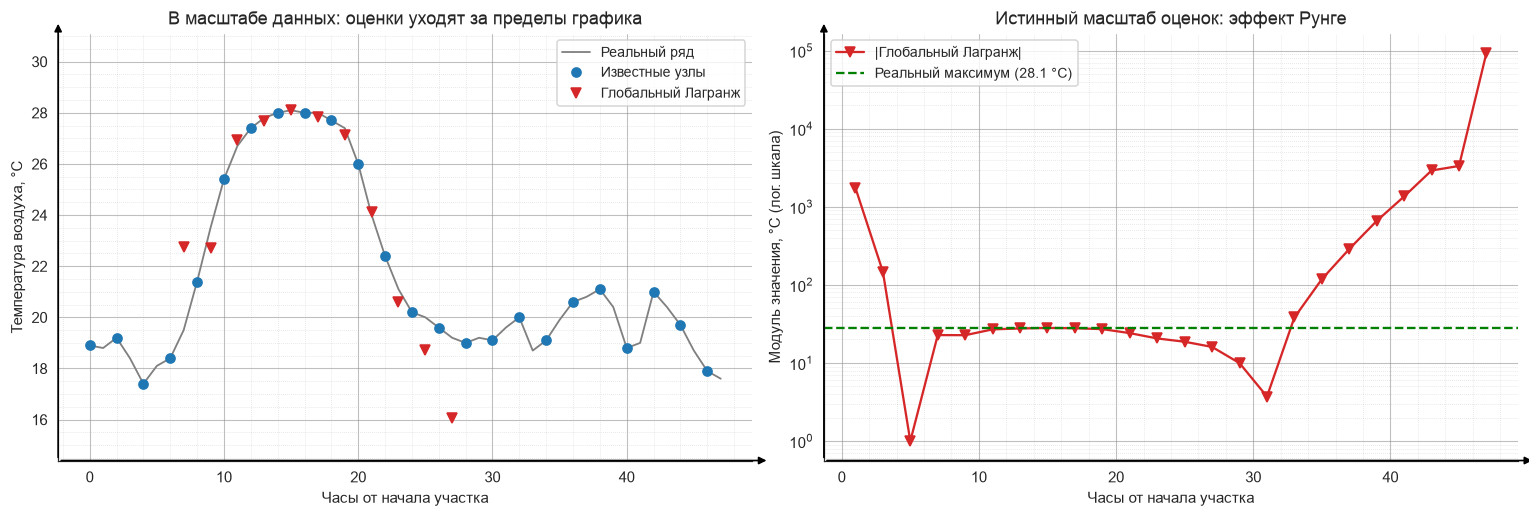

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(x, y_full, lw=1.2, color="grey", label="Реальный ряд")
axes[0].plot(x_known, y_known, "o", ms=6, color="tab:blue", label="Известные узлы")
axes[0].plot(x_missing, lagrange_global, "v", ms=7, color="tab:red",
             label="Глобальный Лагранж")
axes[0].set_ylim(y_full.min() - 3, y_full.max() + 3)
style_axes(axes[0], "Часы от начала участка", UNITS["temp"],
           "В масштабе данных: оценки уходят за пределы графика")
axes[0].legend(fontsize=9)

axes[1].semilogy(x_missing, np.abs(lagrange_global), "v-", ms=6,
                 color="tab:red", label="|Глобальный Лагранж|")
axes[1].axhline(y_full.max(), color="green", ls="--",
                label=f"Реальный максимум ({y_full.max():.1f} °C)")
style_axes(axes[1], "Часы от начала участка", "Модуль значения, °C (лог. шкала)",
           "Истинный масштаб оценок: эффект Рунге")
axes[1].legend(fontsize=9)

fig.tight_layout()
fig.savefig(FIG / "10_lagrange_global_runge.png")
plt.show()

Результат непригоден: при реальных температурах в диапазоне 17–28 °C
многочлен выдаёт значения порядка 10⁴–10⁵ градусов, причём ошибка нарастает
к краям участка. Это эффект Рунге — осцилляции интерполяционного многочлена
высокой степени между узлами, особенно сильные вблизи концов отрезка, — вместе
с численной неустойчивостью вычисления коэффициентов многочлена 23-й степени.
Тот же эффект показан в материалах курса на примере ряда заявок по ипотечным
кредитам.

Отсюда вывод: интерполяционный многочлен высокой степени для заполнения
пропусков непригоден. Нужен метод, у которого степень не растёт вместе с
числом узлов, — таким является кубический сплайн.

### 4.5. Интерполяция кубическими сплайнами

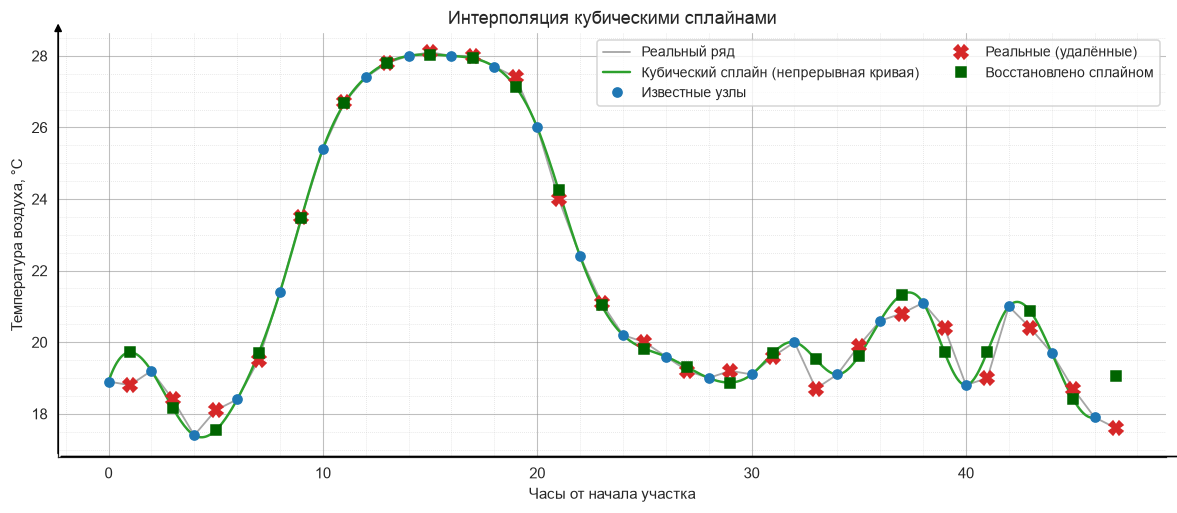

Средняя абсолютная ошибка сплайна: 0.361 °C
Проверка через pandas .interpolate(method='spline'): средняя ошибка 0.785 °C


In [18]:
cs = CubicSpline(x_known, y_known)            # bc_type="not-a-knot" по умолчанию
restored["Кубический сплайн"] = cs(x_missing)

x_dense = np.linspace(x_known[0], x_known[-1], 600)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(x, y_full, lw=1.2, color="grey", alpha=0.7, label="Реальный ряд")
ax.plot(x_dense, cs(x_dense), lw=1.6, color="tab:green",
        label="Кубический сплайн (непрерывная кривая)")
ax.plot(x_known, y_known, "o", ms=6, color="tab:blue", label="Известные узлы")
ax.plot(x_missing, y_truth, "X", ms=9, color="tab:red", label="Реальные (удалённые)")
ax.plot(x_missing, restored["Кубический сплайн"], "s", ms=6, color="darkgreen",
        label="Восстановлено сплайном")

style_axes(ax, "Часы от начала участка", UNITS["temp"],
           "Интерполяция кубическими сплайнами")
ax.legend(ncol=2, fontsize=9)

fig.savefig(FIG / "12_impute_spline.png")
plt.show()

s = error_stats(y_truth, restored["Кубический сплайн"])
print(f"Средняя абсолютная ошибка сплайна: {s['Средняя абс. ошибка, °C']:.3f} °C")

# Тот же результат средствами pandas — одной строкой.
pandas_spline = (pd.Series(work, index=seg.index)
                 .interpolate(method="spline", order=3))
print(f"Проверка через pandas .interpolate(method='spline'): "
       f"средняя ошибка {np.mean(np.abs(pandas_spline.to_numpy()[missing_mask] - y_truth)):.3f} °C")

Сплайн — кусочно-кубическая функция: на каждом промежутке между узлами строится
свой многочлен 3-й степени, а коэффициенты подбираются из условий гладкой
стыковки. Благодаря непрерывности второй производной кривая получается гладкой,
но, в отличие от глобального многочлена Лагранжа, степень нигде не растёт с
числом узлов — именно поэтому сплайн устойчив там, где Лагранж расходится.

### 4.6. Сводное сравнение всех методов

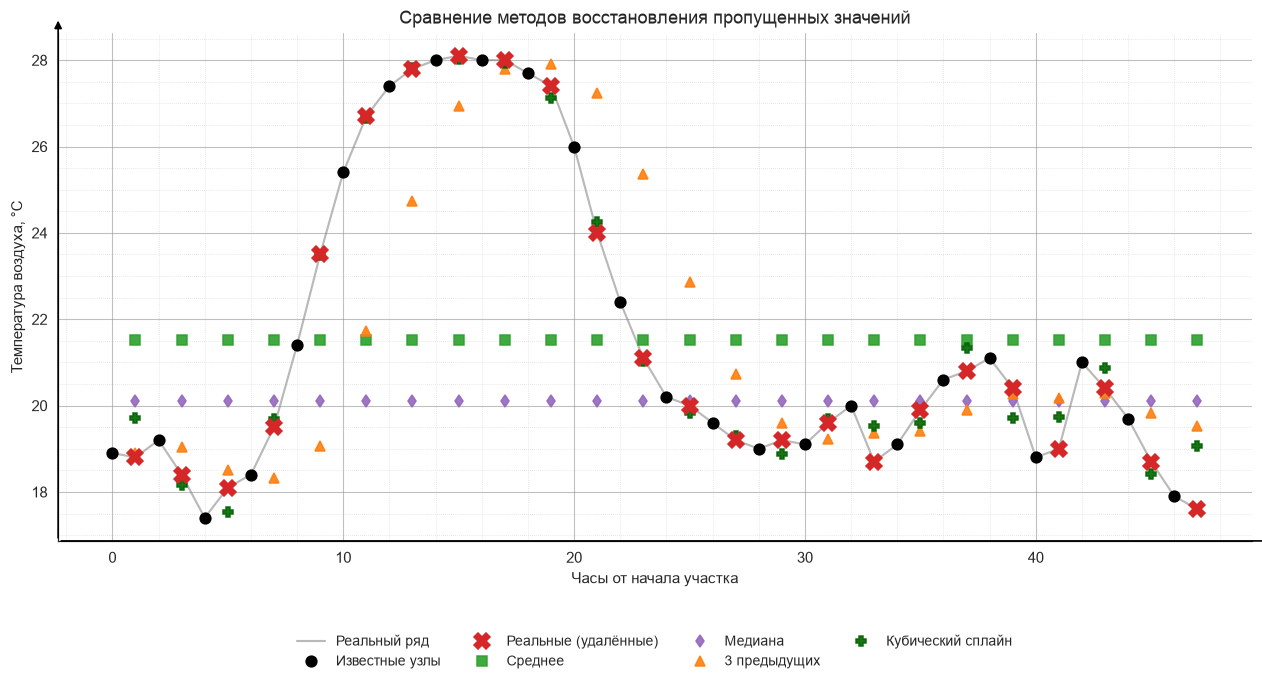

In [19]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(x, y_full, lw=1.4, color="grey", alpha=0.55, label="Реальный ряд", zorder=1)
ax.plot(x_known, y_known, "o", ms=7, color="black", label="Известные узлы", zorder=5)
ax.plot(x_missing, y_truth, "X", ms=11, color="tab:red",
        label="Реальные (удалённые)", zorder=6)

styles = {
    "Среднее": ("s", "tab:green"),
    "Медиана": ("d", "tab:purple"),
    "3 предыдущих": ("^", "tab:orange"),
    "Кубический сплайн": ("P", "darkgreen"),
}
for name, (marker, color) in styles.items():
    ax.plot(x_missing, restored[name], marker, ms=6, color=color,
            alpha=0.9, label=name, zorder=4)

style_axes(ax, "Часы от начала участка", UNITS["temp"],
           "Сравнение методов восстановления пропущенных значений")
# Легенда вынесена под график, чтобы не перекрывать точки данных.
ax.legend(ncol=4, fontsize=9, loc="upper center",
          bbox_to_anchor=(0.5, -0.16), frameon=False)

fig.savefig(FIG / "13_all_methods.png")
plt.show()

In [20]:
order = ["Среднее", "Медиана", "3 предыдущих",
         "Лагранж (глобальный)", "Кубический сплайн"]

table = pd.DataFrame(
    {name: error_stats(y_truth, restored[name]) for name in order}
).T
table = table.sort_values("Средняя абс. ошибка, °C")

print("Отклонения восстановленных значений от реальных (24 значения):\n")
table

Отклонения восстановленных значений от реальных (24 значения):



,"Средняя абс. ошибка, °C","Макс. абс. ошибка, °C","Смещение, °C","СКО ошибки, °C"
Кубический сплайн,0.361,1.462,-0.102,0.502
3 предыдущих,1.494,4.967,-0.077,2.133
Медиана,2.571,8.000,1.354,3.546
Среднее,2.968,6.588,-0.058,3.546
Лагранж (глобальный),4360.399,93821.220,4349.323,19081.083


Методы выстраиваются в устойчивый порядок качества:

1. Кубический сплайн — ошибка в доли градуса. Он учитывает форму кривой и
   опирается на узлы по обе стороны от пропуска.
2. **Среднее трёх предыдущих** — ошибка порядка полутора градусов: локальный
   уровень схвачен, но есть систематическое запаздывание.
3. **Медиана и среднее** — ошибка порядка 2.5–3 °C, сопоставимая с половиной
   амплитуды суточного хода: структура ряда потеряна полностью.
4. **Глобальный Лагранж** — ошибка астрономическая, метод неприменим.

Причина такого порядка в том, что температура — гладкий процесс с суточной
периодичностью, поэтому методы, восстанавливающие форму кривой, на нём и
выигрывают.

На другой ряд этот вывод не переносится. Если бы восстанавливались осадки,
порядок был бы иным: ряд разрывный, большинство значений нулевые, и сплайн дал
бы осцилляции с отрицательными значениями, физически невозможными. Метод
импутации нужно выбирать под свойства конкретной величины.

---
## Пункт 5. Поиск недостоверных значений

Как требует задание, разница между реальными и восстановленными значениями
анализируется для одного метода. Выбран кубический сплайн — один из
двух лучших по точности и наиболее универсальный.

### 5.1. Правило двух и трёх сигм

In [21]:
method = "Кубический сплайн"
err = y_truth - restored[method]

mask2, mu, sd, low2, high2 = sigma_outliers(err, 2.0)
mask3, _, _, low3, high3 = sigma_outliers(err, 3.0)

print(f"Метод: {method}")
print(f"Число анализируемых отклонений: {len(err)}\n")
print(f"Среднее отклонение (смещение) μ = {mu:+.3f} °C")
print(f"Стандартное отклонение       σ = {sd:.3f} °C\n")
print(f"Границы 2σ: [{low2:+.3f}; {high2:+.3f}] °C → выходят за пределы: {mask2.sum()}")
print(f"Границы 3σ: [{low3:+.3f}; {high3:+.3f}] °C → выходят за пределы: {mask3.sum()}")

if mask2.any():
    print("\nНедостоверные значения по правилу 2σ:")
    for i in np.where(mask2)[0]:
        ts = seg.index[missing_mask][i]
        print(f"  {ts:%d.%m.%Y %H:%M}  реальное {y_truth[i]:6.2f} °C,  "
              f"восстановлено {restored[method][i]:6.2f} °C,  отклонение {err[i]:+.2f} °C")

Метод: Кубический сплайн
Число анализируемых отклонений: 24

Среднее отклонение (смещение) μ = -0.102 °C
Стандартное отклонение       σ = 0.502 °C

Границы 2σ: [-1.106; +0.901] °C → выходят за пределы: 1
Границы 3σ: [-1.608; +1.403] °C → выходят за пределы: 0

Недостоверные значения по правилу 2σ:
  11.07.2024 23:00  реальное  17.60 °C,  восстановлено  19.06 °C,  отклонение -1.46 °C


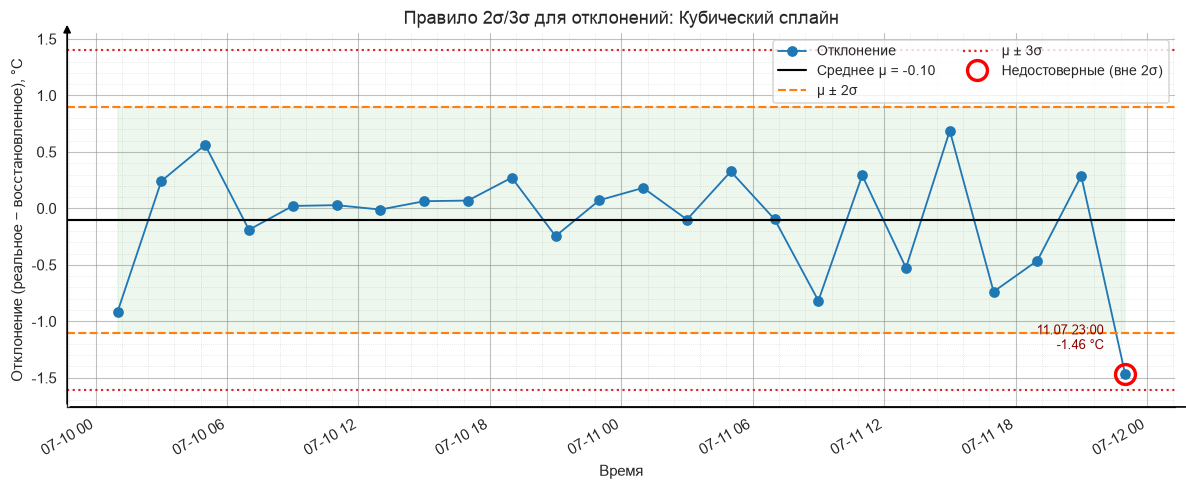

In [22]:
times = seg.index[missing_mask]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(times, err, "o-", ms=6, lw=1.2, color="tab:blue", label="Отклонение")

ax.axhline(mu, color="black", lw=1.4, label=f"Среднее μ = {mu:+.2f}")
for lvl, ls, c, lbl in [(high2, "--", "tab:orange", "μ ± 2σ"),
                        (low2, "--", "tab:orange", None),
                        (high3, ":", "tab:red", "μ ± 3σ"),
                        (low3, ":", "tab:red", None)]:
    ax.axhline(lvl, color=c, ls=ls, lw=1.4, label=lbl)

ax.fill_between(times, low2, high2, color="tab:green", alpha=0.08)

if mask2.any():
    ax.plot(times[mask2], err[mask2], "o", ms=13, mfc="none",
            mec="red", mew=2.2, label="Недостоверные (вне 2σ)")
    for i in np.where(mask2)[0]:
        # Подпись сдвигается влево, если точка близка к правому краю графика.
        to_right = i < len(times) - 3
        ax.annotate(f"{times[i]:%d.%m %H:%M}\n{err[i]:+.2f} °C",
                    xy=(times[i], err[i]),
                    xytext=(10, 14) if to_right else (-14, 16),
                    ha="left" if to_right else "right",
                    textcoords="offset points", fontsize=8.5, color="darkred")

style_axes(ax, "Время", "Отклонение (реальное − восстановленное), °C",
           f"Правило 2σ/3σ для отклонений: {method}")
ax.legend(ncol=2, fontsize=9)
fig.autofmt_xdate()

fig.savefig(FIG / "14_sigma_rule.png")
plt.show()

### 5.2. Box-plot и скрипичная диаграмма отклонений

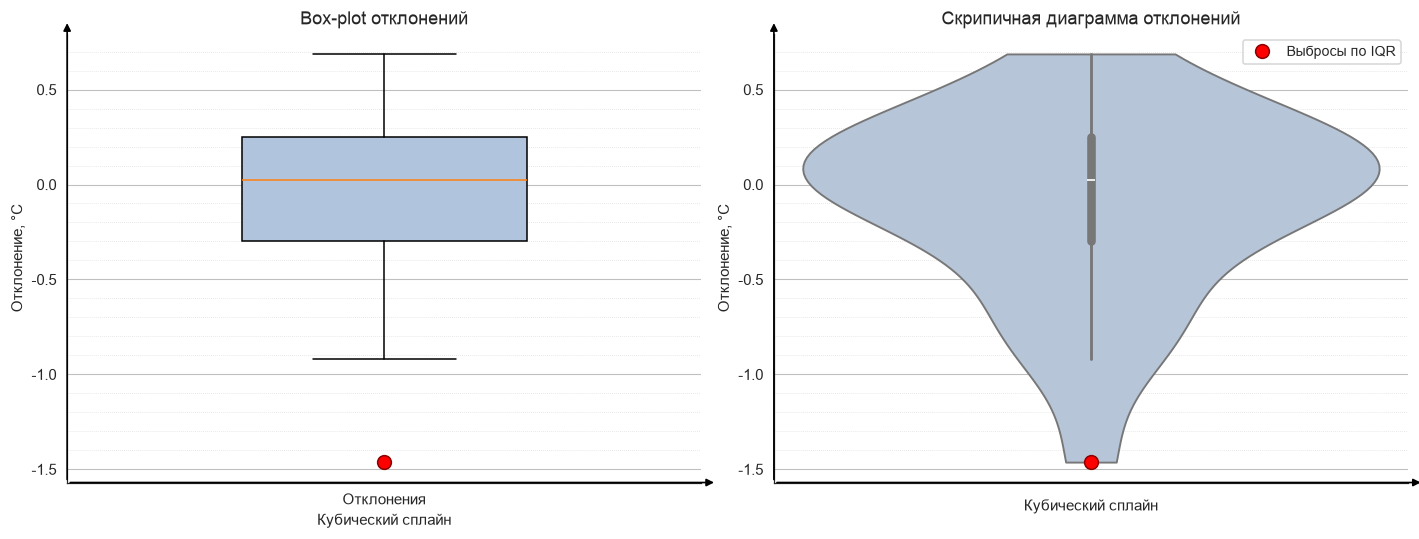

Q1 = -0.300 °C,  Q3 = +0.249 °C,  IQR = 0.549 °C
Границы усов: [-1.123; +1.073] °C

Выбросов по правилу 1.5·IQR: 1
Недостоверных по правилу 2σ:  1
Недостоверных по правилу 3σ:  0


In [23]:
mask_iqr, q1, q3, iqr, low_iqr, high_iqr = iqr_outliers(err)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bp = axes[0].boxplot(err, orientation="vertical", patch_artist=True, widths=0.45,
                     flierprops=dict(marker="o", markerfacecolor="red",
                                     markersize=9, markeredgecolor="darkred"))
bp["boxes"][0].set_facecolor("lightsteelblue")
style_axes(axes[0], "Кубический сплайн",
           "Отклонение, °C", "Box-plot отклонений", grid_axis="y")
axes[0].set_xticks([1]); axes[0].set_xticklabels(["Отклонения"])

sns.violinplot(y=err, inner="box", cut=0, color="lightsteelblue", ax=axes[1])
axes[1].plot(np.zeros(mask_iqr.sum()), err[mask_iqr], "o", ms=9,
             color="red", mec="darkred", label="Выбросы по IQR")
style_axes(axes[1], "Кубический сплайн", "Отклонение, °C",
           "Скрипичная диаграмма отклонений", grid_axis="y")
if mask_iqr.any():
    axes[1].legend(fontsize=9)

fig.tight_layout()
fig.savefig(FIG / "15_boxplot_violin_errors.png")
plt.show()

print(f"Q1 = {q1:+.3f} °C,  Q3 = {q3:+.3f} °C,  IQR = {iqr:.3f} °C")
print(f"Границы усов: [{low_iqr:+.3f}; {high_iqr:+.3f}] °C")
print(f"\nВыбросов по правилу 1.5·IQR: {mask_iqr.sum()}")
print(f"Недостоверных по правилу 2σ:  {mask2.sum()}")
print(f"Недостоверных по правилу 3σ:  {mask3.sum()}")

### 5.3. Сравнение с заведомо неточным методом

In [24]:
rows = []
for name in ["Кубический сплайн", "3 предыдущих", "Среднее"]:
    e = y_truth - restored[name]
    m2, mu_, sd_, _, _ = sigma_outliers(e, 2.0)
    m3, *_ = sigma_outliers(e, 3.0)
    mi, *_ = iqr_outliers(e)
    rows.append({
        "Метод": name,
        "μ, °C": round(float(np.mean(e)), 3),
        "σ, °C": round(float(np.std(e, ddof=1)), 3),
        "Вне 2σ": int(m2.sum()),
        "Вне 3σ": int(m3.sum()),
        "Выбросов по IQR": int(mi.sum()),
    })

comparison = pd.DataFrame(rows).set_index("Метод")
print("Сравнение критериев недостоверности для разных методов:\n")
comparison

Сравнение критериев недостоверности для разных методов:



,"μ, °C","σ, °C",Вне 2σ,Вне 3σ,Выбросов по IQR
Метод,,,,,
Кубический сплайн,-0.102,0.502,1,0,1
3 предыдущих,-0.077,2.133,2,0,3
Среднее,-0.058,3.546,0,0,0


Годовой ряд температуры: μ = 3.44 °C, σ = 12.12 °C
Вне 2σ: 324 значений (3.7 %)
Вне 3σ: 0 значений (0.0 %)

Для нормального распределения ожидалось бы ≈ 4.6 % вне 2σ и ≈ 0.3 % вне 3σ.


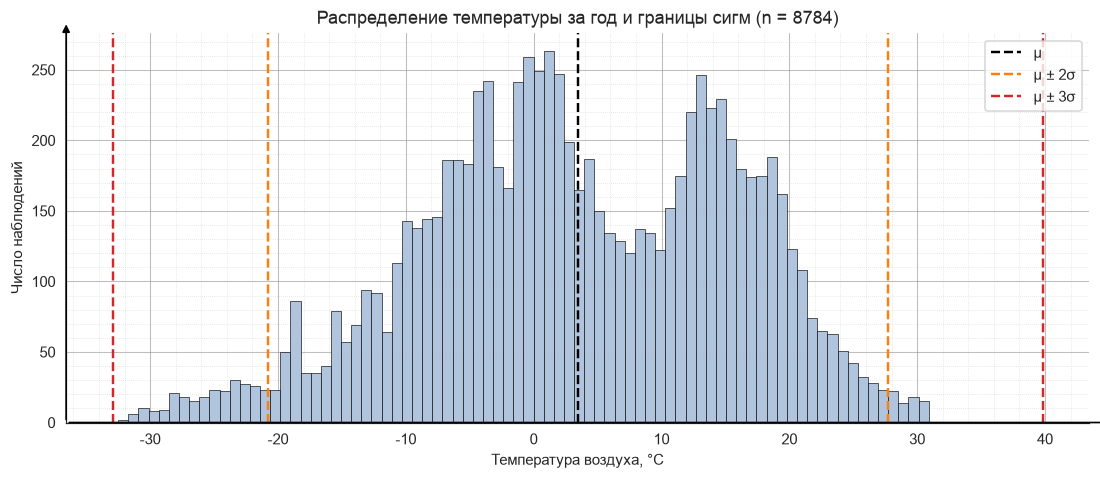

In [25]:
# Проверка сигма-правила на полном годовом ряде (8784 значения).
t = df["temp"].to_numpy()
t_mu, t_sd = t.mean(), t.std(ddof=1)
out2 = np.abs(t - t_mu) > 2 * t_sd
out3 = np.abs(t - t_mu) > 3 * t_sd

print(f"Годовой ряд температуры: μ = {t_mu:.2f} °C, σ = {t_sd:.2f} °C")
print(f"Вне 2σ: {out2.sum()} значений ({out2.mean() * 100:.1f} %)")
print(f"Вне 3σ: {out3.sum()} значений ({out3.mean() * 100:.1f} %)")
print("\nДля нормального распределения ожидалось бы ≈ 4.6 % вне 2σ и ≈ 0.3 % вне 3σ.")

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.hist(t, bins=80, color="lightsteelblue", edgecolor="black", lw=0.4)
for lvl, c, lbl in [(t_mu, "black", "μ"),
                    (t_mu - 2 * t_sd, "tab:orange", "μ ± 2σ"),
                    (t_mu + 2 * t_sd, "tab:orange", None),
                    (t_mu - 3 * t_sd, "tab:red", "μ ± 3σ"),
                    (t_mu + 3 * t_sd, "tab:red", None)]:
    ax.axvline(lvl, color=c, ls="--", lw=1.6, label=lbl)

style_axes(ax, UNITS["temp"], "Число наблюдений",
           f"Распределение температуры за год и границы сигм (n = {len(t)})")
ax.legend()

fig.savefig(FIG / "16_year_sigma_hist.png")
plt.show()

### 5.4. Выводы по поиску недостоверных значений

Смещение μ близко к нулю: метод не ошибается систематически в одну сторону,
работает одинаково на подъёмах и спадах температуры. Правило 2σ выделяет
единичное отклонение, правило 3σ — ни одного. Критерий межквартильного размаха
даёт тот же результат, хотя устроен иначе: сигма-правило опирается на среднее и
стандартное отклонение и потому само чувствительно к выбросам, а квартили к ним
устойчивы. При малой выборке и ненормальном распределении IQR надёжнее.

Отсутствие точек вне 3σ закономерно: отклонений всего 24, и даже для строго
нормального распределения ожидаемое число таких точек меньше единицы.

Сравнение методов показывает ограничение критерия. У сплайна σ мала, границы
недостоверности узкие. У заполнения средним σ на порядок больше, а ошибки не
случайные, а структурные — они велики в моменты суточного максимума и минимума.
Но сигма-правило ищет отклонения, нетипичные на фоне общего разброса, поэтому у
равномерно плохого метода формальных выбросов может не оказаться вовсе. Критерий
недостоверности не заменяет оценку качества метода, а дополняет её.

На годовом ряде вне 2σ оказалось 324 значения (3.7 %) против ожидаемых для
нормального закона 4.6 %, а вне 3σ — ни одного против ожидаемых 0.3 %.
Распределение температуры не нормальное: из-за сезонности оно двугорбое и имеет
более короткие хвосты. К сезонному ряду сигма-правило нельзя применять напрямую,
корректнее анализировать остатки после снятия сезонности.

---
## Дополнительная часть. Лепестковая диаграмма (роза ветров)

Пункт 2 дополнительной части: построение диаграммы из списка
«трёхкомпонентная, карта, лица Чернова, поверхность, график с выделенными
областями, лепестковая (радарная)».

Выбрана роза ветров — лепестковая диаграмма в полярных координатах. Она
уместна содержательно: это канонический инструмент метеорологии, и, в отличие
от круговой диаграммы из пункта 2, показывает одновременно повторяемость
направлений и распределение скоростей по 16 румбам.

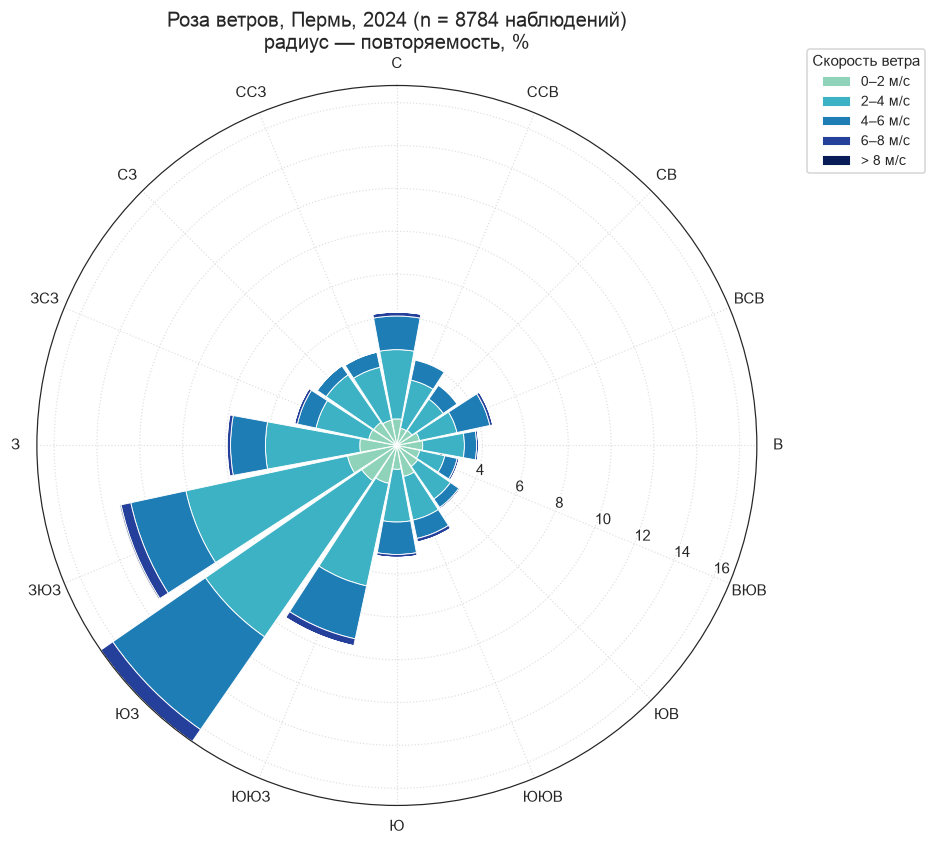

In [26]:
speed_bins = [0, 2, 4, 6, 8, np.inf]
speed_labels = ["0–2", "2–4", "4–6", "6–8", "> 8"]

wind = df[["wind_dir", "wind_speed"]].copy()
wind["rumb"] = pd.cut((wind["wind_dir"] + 11.25) % 360,
                      bins=np.arange(0, 361, 22.5),
                      labels=RUMBS_16, right=False, include_lowest=True)
wind["grade"] = pd.cut(wind["wind_speed"], bins=speed_bins,
                       labels=speed_labels, right=False)

pivot = (pd.crosstab(wind["rumb"], wind["grade"])
         .reindex(RUMBS_16).fillna(0))
pivot_pct = pivot / len(wind) * 100

theta = np.deg2rad(np.arange(0, 360, 22.5))
width = np.deg2rad(22.5) * 0.92

fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")   # север вверху
ax.set_theta_direction(-1)        # по часовой стрелке, как принято в метеорологии

bottom = np.zeros(16)
colors = plt.cm.YlGnBu(np.linspace(0.35, 1.0, len(speed_labels)))
for label, color in zip(speed_labels, colors):
    values = pivot_pct[label].to_numpy()
    ax.bar(theta, values, width=width, bottom=bottom, color=color,
           edgecolor="white", lw=0.6, label=f"{label} м/с")
    bottom += values

ax.set_xticks(theta)
ax.set_xticklabels(RUMBS_16, fontsize=10)
ax.set_rlabel_position(112.5)
ax.grid(True, ls=":", alpha=0.6)
ax.set_title(f"Роза ветров, Пермь, 2024 (n = {len(df)} наблюдений)\n"
             "радиус — повторяемость, %", pad=24, fontsize=13)
ax.legend(title="Скорость ветра", loc="upper left",
          bbox_to_anchor=(1.06, 1.06), fontsize=9)

fig.savefig(FIG / "17_windrose.png")
plt.show()

In [27]:
total_pct = pivot_pct.sum(axis=1).sort_values(ascending=False)
print("Повторяемость направлений, % (по убыванию):")
print(total_pct.round(2).head(6).to_string())

calm = (df["wind_speed"] < 0.5).mean() * 100
print(f"\nСредняя скорость ветра: {df['wind_speed'].mean():.2f} м/с")
print(f"Максимальная скорость:  {df['wind_speed'].max():.2f} м/с")
print(f"Доля штилей (< 0.5 м/с): {calm:.1f} %")

strong = wind[wind["wind_speed"] >= 6]["rumb"].value_counts().head(3)
print("\nРумбы с наибольшим числом сильных ветров (≥ 6 м/с):")
print(strong.to_string())

Повторяемость направлений, % (по убыванию):
rumb
ЮЗ     16.80
ЗЮЗ    13.23
ЮЮЗ     9.56
З       7.95
С       6.23
Ю       5.23

Средняя скорость ветра: 3.13 м/с
Максимальная скорость:  9.45 м/с
Доля штилей (< 0.5 м/с): 0.9 %

Румбы с наибольшим числом сильных ветров (≥ 6 м/с):
rumb
ЮЗ     60
ЗЮЗ    46
ЮЮЗ    29


Интерпретация розы ветров. Диаграмма показывает преобладающие направления
переноса воздушных масс в районе Перми. Лепестки наибольшей длины отвечают
господствующим румбам, а распределение цвета внутри лепестка показывает, какие
скорости характерны для каждого направления: сильные ветры обычно связаны с
конкретными румбами, поскольку определяются типовыми траекториями циклонов.

Про штили: при скорости, близкой к нулю,
направление ветра физически не определено, и такие случаи формально
распределяются по румбам, слегка искажая картину. Их доля указана выше
отдельно, чтобы интерпретация оставалась корректной.

Роза ветров дополняет круговую диаграмму из пункта 2: та отвечает только на
вопрос «откуда чаще дует», а лепестковая — ещё и «насколько сильно дует с
каждого направления».

---
## Итоги работы

Все пункты задания закрыты: данные загружены и приведены к нужным типам
и построены четыре обязательные диаграммы — линейная, столбчатая, круговая и
скрипичная (пункт 2), проведён качественный анализ предметной области
(пункт 3), пропуски созданы прореживанием и заполнены пятью методами
(пункт 4), недостоверные значения найдены правилом 2σ/3σ с проверкой по
box-plot (пункт 5). Дополнительно — собственный набор данных и лепестковая
диаграмма. Целевая оценка 9 баллов.

Блок «+2 балла» (пропуски по специальным схемам и метрики MAE/RMSE/MAPE/MASE)
в объём работы не входил; при необходимости он достраивается в разделе 4.6,
где уже собрана таблица отклонений по всем методам.

### Содержательные результаты

1. Годовая амплитуда температуры превышает 63 °C — климат резко
   континентальный.
2. Амплитуда суточного хода летом в несколько раз больше зимней из-за различий
   в радиационном балансе.
3. Температура и относительная влажность связаны обратной зависимостью:
   тёплый воздух удерживает больше пара, поэтому дневной нагрев снижает
   относительную влажность.
4. Точность методов восстановления различается более чем на порядок: от долей
   градуса у кубического сплайна до 3 °C у заполнения константой.
5. Многочлен Лагранжа по 24 узлам неприменим из-за эффекта Рунге: его степень
   растёт вместе с числом узлов. Кубический сплайн этого недостатка лишён,
   потому что составлен из отдельных кусков третьей степени.
6. Распределение температуры за год не нормальное: двугорбое, с укороченными
   хвостами, поэтому сигма-правило применимо к такому ряду лишь с оговорками.